[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/NOAA-EPIC/EAGLE/blob/main/notebooks/global_mini.ipynb)

# Welcome to the EAGLE pipeline!

Before we start, let's go over a few Google Colab tips!

Q) Where are files located?!

A) You should see a navigation bar on the left of your screen. The 6th option looks like a folder. Click on that and you will see all files in your workspace. If you have not run anything yet, you should only see a "sample data" folder (this automatically populates in any colab notebook). Throughout this notebook you can go into this area and watch your files populate, look at plots, and edit yamls if you wish to update any configurations on your own. Note: sometimes clicking through folders can be a little laggy.

Q) How do I connect to compute?!

A) You will need to connect to a runtime. Towards the top right of your screen you will see the words RAM and disk. There is a drop down button next to that. Click there, and then click "change runtime type". Make sure "Python 3" is selected under runtime type, and if available, select a T4 GPU as your hardware accelerator. If not available, you can run this notebook with a CPU but it will be very, very slow during training. If you happen to have credits for an A-100, use that! All estimated run times in this notebook are from using a T4 GPU.

Now that you are connected to compute and know where to find your files, let's do some machine learning!

This notebook will guide you through an entire ML pipeline.
1) Data preprocessing using `ufs2arco` to create training and validation datasets
2) Model training using `anemoi-core` modules to train a graph-based model
3) Creating a forecast with `anemoi-inference` to run inference from a model checkpoint
4) Postprocessing inference output with `eagle-tools` to make it more user-friendly and compatible with downstream applications
5) Verifying your forecast (or multiple!) with `wxvx` to verify against the Global Forecast System (GFS) and observations

More information about the various modules and instructions will be provided within each individual step. You will also find additional instructions if you wish to change configurations yourself at all!

### Step 1: Environment Setup
Runtime: ~4 minutes

You will receive a popup after all packages are installed. Click "restart session" on the popup and continue on to the next step.

In [ ]:
!pip install -q condacolab
import condacolab

condacolab.install()

Note: You may get a message that says "Your session crashed. Automatically restarting." The session will restart with the fresh conda install. This is not an error, and you can continue.

Clone repository

After executing this cell you should see the `EAGLE` repository along with `sample_data` to the left of your screen.

In [ ]:
!git clone https://github.com/NOAA-EPIC/EAGLE.git

Create environments

~15 minutes

We create 4 separate conda environments:
1) base: used for config generation
2) data: used to create training data or initial conditions for inference
3) anemoi: used for model training and inference
4) wxvx: used for forecast verification

In [ ]:
!conda env update --quiet --name base --file envs/base.yaml

In [ ]:
!conda env create --quiet --name data --file envs/data.yaml

In [ ]:
!sed 's/- mkl .*/- mkl 2026.1.0.*/' -i envs/anemoi.yaml
!conda env create --quiet --name anemoi --file envs/anemoi.yaml

In [ ]:
!conda env create --quiet --name wxvx --file envs/wxvx.yaml

In [ ]:
# a few packages we need for plotting results
!pip install xarray==2026.2.* matplotlib "zarr<3"

In [ ]:
# clean up conda and pip caches to save space
!conda clean --all --yes && pip cache purge

### Step 2: Compose our main config with uwtools

Runtime: Immediate

In [ ]:
%cd /content/EAGLE/

!conda run -n base uw config compose config/base.yaml config/global_mini.yaml config/colab.yaml >eagle.yaml

### Step 3: Create training and validation datasets with ufs2arco

Runtime: ~7 minutes

`ufs2arco` is a python package developed by NOAA Physical Sciences Laboratory (PSL) that is designed to make NOAA forecast, reanalysis, and reforecast datasets more accessible for scientific analysis and machine learning model development. The name stems from its original intent, which was to transform output from the Unified Forecast System (UFS) into Analysis Ready, Cloud Optimized (ARCO; Abernathey et al., (2021)) format. However, the package now pulls data from a number of non-UFS sources, including GFS/GEFS before UFS was created, and even ECMWF's ERA5 dataset.

To learn more about ufs2arco, check out the documentation: https://ufs2arco.readthedocs.io/en/latest/index.html

We are going to create the following dataset:
- GFS Initial Conditions
- 6-hour
- Training data dates: 2022-01-01T00 - 2022-01-01T18
- Validation data dates: 2022-01-02T00 - 2022-01-02T18
- 1-degree global resolution

For the purposes of running this notebook, we will not be creating a test set.

While this cell is running, go into the `/content/EAGLE/run/global_mini/data` folder and look at `logs/logs.serial.out`. This will provide more insight into the dataset creation. Additionally, open `ufs2arco-gfs.yaml` to see all configurations related to data preprocessing.

Note: ufs2arco has the capability to parallelize data loading with MPI. We are not taking full advantage of that capability in this notebook. If you wish to use that capability, go see ufs2arco documentation!

Create static file for regridding GFS from 0.25 degree --> 1 degree

In [ ]:
!conda run -n data uw execute \
  --config-file eagle.yaml \
  --module eagle/data/grids_and_meshes.py \
  --classname GridsAndMeshes \
  --task provisioned_rundir

Prepare training data

In [ ]:
!conda run -n data uw execute \
  --config-file eagle.yaml \
  --module eagle/data/zarr.py \
  --classname Zarr \
  --task run \
  --key-path zarrs.gfs

After the dataset has completed, let's view it!

You will notice that this format looks different than a "typical" gridded netCDF or Zarr file. Take note of the flattened grid, statistics, NaN flag, and attributes. These important details make the dataset ready to be used within an ML model.

In [ ]:
import xarray as xr

ufs2arco_ds = xr.open_zarr("/content/EAGLE/run/global_mini/data/gfs.zarr")
ufs2arco_ds

<xarray.Dataset> Size: 383MB
Dimensions:                           (variable: 92, time: 16, ensemble: 1,
                                       cell: 64800)
Coordinates:
  * variable                          (variable) int64 736B 0 1 2 3 ... 89 90 91
  * time                              (time) int64 128B 0 1 2 3 ... 12 13 14 15
  * ensemble                          (ensemble) int64 8B 0
  * cell                              (cell) int64 518kB 0 1 2 ... 64798 64799
Data variables: (12/22)
    count                             (variable) float64 736B ...
    count_array                       (time, variable, ensemble) float64 12kB ...
    data                              (time, variable, ensemble, cell) float32 382MB ...
    dates                             (time) datetime64[s] 128B ...
    has_nans                          (variable) bool 92B ...
    has_nans_array                    (time, variable, ensemble) bool 1kB ...
    ...                                ...
    statistics_tendencies_6h_mean     (variable) float64 736B ...
    statistics_tendencies_6h_minimum  (variable) float64 736B ...
    statistics_tendencies_6h_stdev    (variable) float64 736B ...
    stdev                             (variable) float64 736B ...
    sums                              (variable) float64 736B ...
    sums_array                        (time, variable, ensemble) float64 12kB ...
Attributes: (12/16)
    allow_nans:              True
    end_date:                2022-01-05T00:00:00
    ensemble_dimension:      1
    field_shape:             [180, 360]
    flatten_grid:            True
    frequency:               6h
    ...                      ...
    stack_order:             ['latitudes', 'longitudes']
    start_date:              2022-01-01T06:00:00
    statistics_end_date:     2022-01-02T18:00:00
    statistics_start_date:   2022-01-01T06:00:00
    variables:               ['cos_julian_day', 'cos_latitude', 'cos_local_ti...
    variables_metadata:      {'accum_tp': {'mars': {'date': '20220101', 'para...

### Step 4: Train a model with anemoi-core modules

Runtime: ~7 minutes

We train a graph-based model with the `anemoi-core` modules from the European Centre for Medium-Range Weather Forecasts (ECMWF). The modules include the following:
- `anemoi-graphs`: https://anemoi.readthedocs.io/projects/graphs/en/latest/
- `anemoi-training`: https://anemoi.readthedocs.io/projects/training/en/latest/
- `anemoi-models`: https://anemoi.readthedocs.io/projects/models/en/latest/

Training is executed using `anemoi-training`.

While training is running, go to the `/content/EAGLE/run/global_mini/training/outputs` folder. You will see folders containing checkpoints and plots from your run.

In [ ]:
!conda run -n anemoi uw execute \
  --config-file eagle.yaml \
  --module eagle/training/training.py \
  --classname Training \
  --task run

### Step 5: Create a forecast with anemoi-inference

Runtime: ~20 seconds (will take a few minutes if on a CPU)

Documentation: https://anemoi.readthedocs.io/projects/inference/en/latest/

Next, we will run inference by executing `anemoi-inference` with `eagle-tools`. We will create a 48 hour forecast from 01/05/2022 0Z to 01/07/2022 00Z using a checkpoint from the model we just trained.

In [ ]:
!conda run -n anemoi uw execute \
  --config-file eagle.yaml \
  --module eagle/inference/inference.py \
  --classname Inference \
  --task run

View inference

Feel free to change the variable or forecast hour that you plot! You can see variable options within the opened dataset below. Simply change the `variable_to_plot` or `fhr_index` variables to update.

In [ ]:
import xarray as xr
ds = xr.open_dataset("/content/EAGLE/run/global_mini/inference/output/2022-01-02T00.12h.nc")
ds

<xarray.Dataset> Size: 105MB
Dimensions:                  (time: 5, values: 64800)
Coordinates:
  * time                     (time) datetime64[ns] 40B 2022-01-03T12:00:00 .....
    forecast_period          (time) int64 40B ...
    latitude                 (values) float32 259kB ...
    longitude                (values) float32 259kB ...
    forecast_reference_time  datetime64[ns] 8B ...
Dimensions without coordinates: values
Data variables: (12/81)
    gh_100                   (time, values) float32 1MB ...
    gh_1000                  (time, values) float32 1MB ...
    gh_150                   (time, values) float32 1MB ...
    gh_200                   (time, values) float32 1MB ...
    gh_250                   (time, values) float32 1MB ...
    gh_300                   (time, values) float32 1MB ...
    ...                       ...
    w_700                    (time, values) float32 1MB ...
    w_850                    (time, values) float32 1MB ...
    w_925                    (time, values) float32 1MB ...
    u80                      (time, values) float32 1MB ...
    v80                      (time, values) float32 1MB ...
    accum_tp                 (time, values) float32 1MB ...

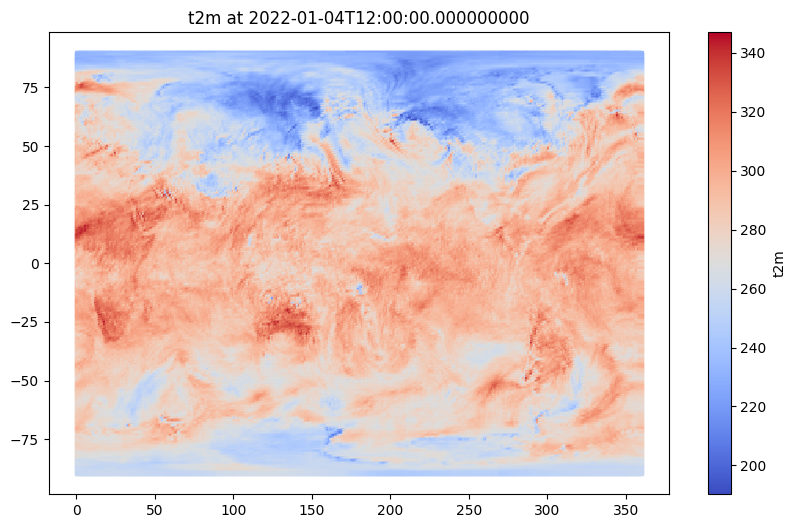

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

variable_to_plot = "t2m"
fhr_index = 2

var = ds[variable_to_plot].isel(time=fhr_index).values
lat = ds['latitude'].values
lon = ds['longitude'].values

plt.figure(figsize=(10, 6))
plt.scatter(lon, lat, c=var, s=10, marker='s', cmap='coolwarm')
plt.colorbar(label=variable_to_plot)
plt.title(f'{variable_to_plot} at {ds["time"][fhr_index].values}')
plt.show()

# Coming soon!

Over the coming weeks the EPIC team will add the following features to this notebook:
1. Users will be able to load a checkpoint that was pretrained for 40,000 steps from an Azure bucket.
2. After loading this checkpoint, users will run near-real-time inference.
3. The notebook will then conclude with verifying that forecast. The forecast will be a few days old so that we can verify it.
4. Ensure this notebook can run end-to-end on CPU only.